# Workshop 2: Scikit-learn and the ML Workflow

## 1. Overview & Setup

### 1.1 Overview
This workshop introduces **Scikit-learn**, the reference Python library for classical machine learning. We will execute the eight steps of an ML workflow on a classification example (Wisconsin Breast Cancer dataset) and a regression example (synthetic server response time).

### 1.2 Setup & Imports
We import the necessary libraries: `numpy`, `pandas`, `matplotlib`, and `sklearn`.


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print(f"Scikit-learn version: {sklearn.__version__}")


Scikit-learn version: 1.6.1


## 2. Part 1: Scikit-learn

### 2.1 The Estimator Interface
Scikit-learn provides a uniform estimator interface with core methods:
- `model = Algorithm(hyper_parameters)`: Select model family & hyper-parameters.
- `model.fit(X_train, y_train)`: Learn parameters from training data.
- `model.predict(X_new)`: Predict class or value for new data.
- `model.predict_proba(X_new)`: Output class probabilities (classification).
- `model.score(X_test, y_test)`: Compute default performance metric.
- `scaler.fit_transform(X_train)` / `scaler.transform(X_test)`: Preprocessing.

### 2.2 The 8 Steps of the ML Workflow Mapped to Tools
1. **Define the problem**: Identify input features $X$, target $y$, and problem type.
2. **Collect and explore**: `pd.DataFrame`, `describe()`, `value_counts()`, plots.
3. **Prepare**: `train_test_split`, `StandardScaler`, `OneHotEncoder`.
4. **Select a model**: `LogisticRegression()`, `DecisionTreeClassifier()`, etc.
5. **Train**: `model.fit(X_train, y_train)`.
6. **Evaluate**: `confusion_matrix`, `precision_score`, `recall_score`, `r2_score`.
7. **Tune**: `cross_val_score`, `GridSearchCV`, `predict_proba`.
8. **Deploy & Monitor**: `joblib.dump` / `joblib.load`, prediction wrapper function.


## 3. Part 2: The Eight Steps on a Classification Example

### Step 1: Define the Problem
- **Input $X$**: 30 tumour measurements (radius, texture, area, etc.).
- **Output $y$**: Binary classification — Benign (0) vs. Malignant (1, positive class).
- **Goal**: Catch malignant tumours. Missing a malignant tumour (False Negative) is worse than a false alarm (False Positive).


### Step 2: Load and Explore the Data


In [15]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
# Scikit-learn codes benign=1, malignant=0 by default. We recode so malignant=1.
y = pd.Series(1 - data.target, name="malignant")

print("Dataset shape:", X.shape)
print("Class distribution:")
print(y.value_counts())

print("First 5 features descriptive statistics:")
print(X.iloc[:, :5].describe().round(1))

print("Mean feature values by class (first 5 features):")
print(X.groupby(y).mean().iloc[:, :5].round(1))


Dataset shape: (569, 30)
Class distribution:
malignant
0    357
1    212
Name: count, dtype: int64
First 5 features descriptive statistics:
       mean radius  mean texture  mean perimeter  mean area  mean smoothness
count        569.0         569.0           569.0      569.0            569.0
mean          14.1          19.3            92.0      654.9              0.1
std            3.5           4.3            24.3      351.9              0.0
min            7.0           9.7            43.8      143.5              0.1
25%           11.7          16.2            75.2      420.3              0.1
50%           13.4          18.8            86.2      551.1              0.1
75%           15.8          21.8           104.1      782.7              0.1
max           28.1          39.3           188.5     2501.0              0.2
Mean feature values by class (first 5 features):
           mean radius  mean texture  mean perimeter  mean area  \
malignant                                          

### Step 3: Prepare (Split then Scale)

**The Golden Rule**: Always split the dataset into training and test sets *before* applying scaling. Scaling parameters (mean and standard deviation) must be calculated exclusively on the training set to prevent **data leakage**.


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

X_train shape: (426, 30), X_test shape: (143, 30)


### Steps 4 & 5: Choose a Model and Train It


In [17]:
from sklearn.linear_model import LogisticRegression

# Step 4: Model Selection
model = LogisticRegression(max_iter=1000)

# Step 5: Training (Gradient descent)
model.fit(X_train_s, y_train)

print("Accuracy on train:", round(model.score(X_train_s, y_train), 3))
print("Accuracy on test: ", round(model.score(X_test_s, y_test), 3))


Accuracy on train: 0.988
Accuracy on test:  0.965


### Step 6: Evaluate with Metrics


Confusion Matrix:
[[89  1]
 [ 4 49]]


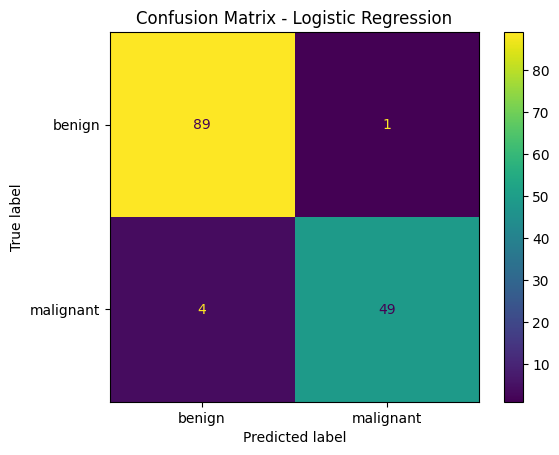

Precision: 0.98
Recall:    0.925
F1 Score:  0.951


In [18]:
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score
)

y_pred = model.predict(X_test_s)
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(cm, display_labels=["benign", "malignant"])
disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:   ", round(recall_score(y_test, y_pred), 3))
print("F1 Score: ", round(f1_score(y_test, y_pred), 3))


### Step 7: Tune Threshold and Compare Algorithms

#### 7.1 Moving Decision Threshold


In [19]:
y_prob = model.predict_proba(X_test_s)[:, 1]

for t in [0.3, 0.5, 0.7]:
    yp = (y_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
    print(f"Threshold (t={t:.1f}): missed malignant (FN) = {fn:2d}, false alarms (FP) = {fp:2d}")


Threshold (t=0.3): missed malignant (FN) =  2, false alarms (FP) =  1
Threshold (t=0.5): missed malignant (FN) =  4, false alarms (FP) =  1
Threshold (t=0.7): missed malignant (FN) =  5, false alarms (FP) =  0


#### 7.2 Compare Algorithms via Cross-Validation Pipeline


In [20]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

candidates = {
    "logistic regression": LogisticRegression(max_iter=1000),
    "decision tree": DecisionTreeClassifier(random_state=42),
    "k-nearest neighbours": KNeighborsClassifier(5),
    "random forest": RandomForestClassifier(random_state=42)
}

for name, algo in candidates.items():
    pipe = make_pipeline(StandardScaler(), algo)
    scores = cross_val_score(pipe, X_train, y_train, cv=5)
    print(f"{name:22s} mean accuracy: {scores.mean():.3f}")


logistic regression    mean accuracy: 0.977
decision tree          mean accuracy: 0.908
k-nearest neighbours   mean accuracy: 0.962
random forest          mean accuracy: 0.965


### Step 8: Save, Reload, and Inference


In [21]:
import joblib

final = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
print("Final test accuracy:", round(final.score(X_test, y_test), 3))

# Export model file
joblib.dump(final, "tumor_model.joblib")

# Load model file
loaded_model = joblib.load("tumor_model.joblib")

# Run inference on a single observation (1-row DataFrame)
new_case = X_test.iloc[[0]]
pred_class = loaded_model.predict(new_case)
pred_prob = loaded_model.predict_proba(new_case).round(3)
true_label = int(y_test.iloc[0])

print(f"Predicted class: {pred_class[0]}, Probabilities [benign, malignant]: {pred_prob[0]}, True class: {true_label}")


Final test accuracy: 0.965
Predicted class: 1, Probabilities [benign, malignant]: [0.001 0.999], True class: 1


## 4. Part 3: The Same Workflow for Regression

We apply the identical workflow steps to a regression problem predicting server response time based on system load.


In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Step 2: Synthetic log generation
rng = np.random.default_rng(0)
n = 300
users = rng.integers(50, 1200, n)
cpu = np.clip(0.06 * users + rng.normal(0, 8, n), 2, 100).round(1)
resp = (40 + 0.25 * users + 1.5 * cpu + rng.normal(0, 25, n)).round(8)

srv = pd.DataFrame({"users": users, "cpu": cpu, "response_ms": resp})

# Step 1: Define features and target
Xr, yr = srv[["users", "cpu"]], srv["response_ms"]

# Step 3: Train / Test split
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)

# Steps 4 & 5: Choose model and fit
reg = LinearRegression().fit(Xr_train, yr_train)

# Step 6: Evaluation metrics
pred = reg.predict(Xr_test)
rmse = np.sqrt(mean_squared_error(yr_test, pred))
r2 = r2_score(yr_test, pred)

print("RMSE:", np.round(rmse, 1), "ms")
print("R2:  ", round(r2, 3))
print(f"Equation: response = {reg.intercept_:.1f} + {reg.coef_[0]:.3f} * users + {reg.coef_[1]:.3f} * cpu")

# Step 8: Deployment inference
sample_pred = reg.predict(pd.DataFrame([[800, 60]], columns=["users", "cpu"])).round(0)
print(f"Prediction: {sample_pred[0]} ms for 800 users at 60 % CPU")


RMSE: 21.3 ms
R2:   0.968
Equation: response = 37.1 + 0.242 * users + 1.668 * cpu
Prediction: 331.0 ms for 800 users at 60 % CPU


## 5. Part 4: Exercises, Checkpoint Questions & Homework

### 5.1 Exercises

#### Exercise 1: Model Comparison with Naive Bayes & SVC
In Cell 2.6, add `GaussianNB()` (from `sklearn.naive_bayes import GaussianNB`) and `SVC()` (from `sklearn.svm import SVC`) to the `candidates` dictionary and evaluate cross-validation accuracy. Populate `ex1_scores` dictionary with mean CV scores.


In [23]:
# Write your code here
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

candidates["naive bayes"] = GaussianNB()
candidates["svc"] = SVC()

ex1_scores = {}
for name, algo in candidates.items():
    pipe = make_pipeline(StandardScaler(), algo)
    scores = cross_val_score(pipe, X_train, y_train, cv=5)
    ex1_scores[name] = scores.mean()
    print(f"{name:22s} mean accuracy: {ex1_scores[name]:.3f}")

logistic regression    mean accuracy: 0.977
decision tree          mean accuracy: 0.908
k-nearest neighbours   mean accuracy: 0.962
random forest          mean accuracy: 0.965
naive bayes            mean accuracy: 0.944
svc                    mean accuracy: 0.977


In [24]:
# nbgrader test: Exercise 1 verification Skip it !

In [25]:
# Write your code here
best_algo = max(ex1_scores, key=ex1_scores.get)
print("Best algorithm:", best_algo, "->", round(ex1_scores[best_algo], 3))

Best algorithm: logistic regression -> 0.977


#### Exercise 2: Logistic Regression Without Scaling
Retrain Logistic Regression without scaling (`LogisticRegression(max_iter=1000).fit(X_train, y_train)`). Compute test accuracy as `unscaled_test_acc`.


In [26]:
# Write your code here
unscaled_model = LogisticRegression(max_iter=1000)
unscaled_model.fit(X_train, y_train)          # raw features, no StandardScaler

unscaled_test_acc = unscaled_model.score(X_test, y_test)
scaled_test_acc = model.score(X_test_s, y_test)

print("Test accuracy (unscaled):", round(unscaled_test_acc, 3))
print("Test accuracy (scaled):  ", round(scaled_test_acc, 3))

Test accuracy (unscaled): 0.951
Test accuracy (scaled):   0.965


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [27]:
# nbgrader test: Exercise 2 verification skip it !

### Exercise 3
A hospital says a missed malignant tumour costs 20 times more than a false alarm. Which threshold of Cell 2.5 would you choose, and why?

In [28]:
# Write your code here
# Cost = 20 * FN + 1 * FP for each threshold of Cell 2.5
costs = {}
for th in [0.3, 0.5, 0.7]:
    yp = (y_prob >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
    costs[th] = 20 * fn + fp
    print(f"t={th:.1f}: FN={fn:2d}, FP={fp:2d}, total cost = {costs[th]}")

t = min(costs, key=costs.get)
because = ("A missed malignant tumour (FN) costs 20x more than a false alarm (FP). "
           "Lowering the threshold makes the model flag a tumour as malignant more easily: "
           "FN decreases (higher recall) at the price of a few more FP. "
           "The lowest threshold (t=0.3) minimises the total cost 20*FN + FP.")
print("Chosen threshold:", t)

t=0.3: FN= 2, FP= 1, total cost = 41
t=0.5: FN= 4, FP= 1, total cost = 81
t=0.7: FN= 5, FP= 0, total cost = 100
Chosen threshold: 0.3


In [29]:
# Cell to evaluate the threshold ... skip it !

Q1. In which order: split or scale? Why?

In [30]:
# Write your code here
response_q1 = ("Split first, then scale. The scaler (mean and std) must be fitted on the training set only "
               "(fit_transform on train, transform on test). If we scale before splitting, information from "
               "the test set leaks into training (data leakage) and the evaluation becomes over-optimistic.")
print(response_q1)

Split first, then scale. The scaler (mean and std) must be fitted on the training set only (fit_transform on train, transform on test). If we scale before splitting, information from the test set leaks into training (data leakage) and the evaluation becomes over-optimistic.


Q2. Your model has accuracy 0.99 on a dataset where 1% of the rows are attacks.
Is it a good model?
Which metric do you look at next?

In [31]:
# Write your code here
good_model = False
next_metrics = ("No: a model that always predicts 'normal' already reaches 99% accuracy while detecting 0 attacks "
                "(imbalanced classes). Look at the confusion matrix, recall (attacks caught), precision, "
                "F1-score, and PR-AUC / ROC-AUC.")
print(good_model, "-", next_metrics)

False - No: a model that always predicts 'normal' already reaches 99% accuracy while detecting 0 attacks (imbalanced classes). Look at the confusion matrix, recall (attacks caught), precision, F1-score, and PR-AUC / ROC-AUC.


 **Q3. What is the difference between `predict` and `predict_proba`?**

In [32]:
# Write your code here
response = ("predict returns the final class label (0 or 1), obtained by applying the default threshold 0.5 "
            "on the probability. predict_proba returns the probability of each class (one column per class, "
            "rows sum to 1), which lets us choose our own decision threshold.")
print(response)

predict returns the final class label (0 or 1), obtained by applying the default threshold 0.5 on the probability. predict_proba returns the probability of each class (one column per class, rows sum to 1), which lets us choose our own decision threshold.


- **Q4. Give the regression equivalents of `LogisticRegression`, `accuracy` and `confusion_matrix`.**

In [33]:
# Write your code here
answer_q4 = {
    "LogisticRegression": "LinearRegression (also Ridge, Lasso, DecisionTreeRegressor, RandomForestRegressor...)",
    "accuracy": "R2 score (r2_score) and error metrics: RMSE (mean_squared_error), MAE (mean_absolute_error)",
    "confusion_matrix": "Residuals analysis: residuals = y_true - y_pred, predicted-vs-actual plot / residual plot",
}
for k, v in answer_q4.items():
    print(f"{k:20s} -> {v}")

LogisticRegression   -> LinearRegression (also Ridge, Lasso, DecisionTreeRegressor, RandomForestRegressor...)
accuracy             -> R2 score (r2_score) and error metrics: RMSE (mean_squared_error), MAE (mean_absolute_error)
confusion_matrix     -> Residuals analysis: residuals = y_true - y_pred, predicted-vs-actual plot / residual plot


### 5.2 Homework: ML Workflow on Login Logs

Apply the eight steps to logins log data:
- Define target: `suspicious = failed_attempts >= 5`.
- Features: `hour`, `duration_min`, `night`, and one-hot encoded `country`.
- Train Logistic Regression and Decision Tree.
- Compute confusion matrix and recall on the test set.


In [34]:
# Homework Setup & Implementation
# Write your code here

np.random.seed(42)
n_samples = 500

logins_clean = pd.DataFrame({
    "failed_attempts": np.random.randint(0, 10, size=n_samples),
    "hour": np.random.randint(0, 24, size=n_samples),
    "duration_min": np.random.exponential(scale=15, size=n_samples).round(1),
    "night": np.random.choice([0, 1], size=n_samples),
    "country": np.random.choice(["US", "FR", "CN", "RU", "DE"], size=n_samples)
})

# 1. Target definition
logins_clean["suspicious"] = (logins_clean["failed_attempts"] >= 5).astype(int)

# 2. Features and One-Hot Encoding
# failed_attempts is NOT a feature: the target is defined from it (it would be target leakage)
X_hw = logins_clean[["hour", "duration_min", "night", "country"]]
X_hw = pd.get_dummies(X_hw, columns=["country"], dtype=int)
y_hw = logins_clean["suspicious"]

# 3. Split then scale
X_hw_train, X_hw_test, y_hw_train, y_hw_test = train_test_split(
    X_hw, y_hw, test_size=0.25, random_state=42, stratify=y_hw
)
scaler_hw = StandardScaler()
X_hw_train_s = scaler_hw.fit_transform(X_hw_train)
X_hw_test_s = scaler_hw.transform(X_hw_test)

# 4 & 5. Train models
log_reg_hw = LogisticRegression(max_iter=1000).fit(X_hw_train_s, y_hw_train)
tree_hw = DecisionTreeClassifier(random_state=42).fit(X_hw_train, y_hw_train)

# 6. Evaluate
y_pred_log_hw = log_reg_hw.predict(X_hw_test_s)
y_pred_tree_hw = tree_hw.predict(X_hw_test)

cm_log_hw = confusion_matrix(y_hw_test, y_pred_log_hw)
cm_tree_hw = confusion_matrix(y_hw_test, y_pred_tree_hw)
print("Confusion matrix - Logistic Regression:\n", cm_log_hw)
print("Confusion matrix - Decision Tree:\n", cm_tree_hw)

recall_log_hw = recall_score(y_hw_test, y_pred_log_hw)
recall_tree_hw = recall_score(y_hw_test, y_pred_tree_hw)

print("Logistic Regression - Recall:", round(recall_log_hw, 3))
print("Decision Tree - Recall:      ", round(recall_tree_hw, 3))

Confusion matrix - Logistic Regression:
 [[53 11]
 [52  9]]
Confusion matrix - Decision Tree:
 [[34 30]
 [36 25]]
Logistic Regression - Recall: 0.148
Decision Tree - Recall:       0.41


In [35]:
# nbgrader test: Homework verification skip it !

In [36]:
# Write your code here
eight_steps = {
    1: "Define: target suspicious = failed_attempts >= 5 ; features hour, duration_min, night, country",
    2: "Explore: logins_clean.describe(), suspicious.value_counts()",
    3: "Prepare: pd.get_dummies(country), train_test_split (stratify), StandardScaler fitted on train only",
    4: "Select: LogisticRegression and DecisionTreeClassifier",
    5: "Train: fit on the training set",
    6: "Evaluate: confusion_matrix and recall_score on the test set",
    7: "Tune: predict_proba + threshold, cross_val_score / GridSearchCV",
    8: "Deploy: joblib.dump / joblib.load and a prediction wrapper",
}
for k, v in eight_steps.items():
    print(k, "-", v)
print()
print("Step 2 check:")
print(logins_clean["suspicious"].value_counts())

1 - Define: target suspicious = failed_attempts >= 5 ; features hour, duration_min, night, country
2 - Explore: logins_clean.describe(), suspicious.value_counts()
3 - Prepare: pd.get_dummies(country), train_test_split (stratify), StandardScaler fitted on train only
4 - Select: LogisticRegression and DecisionTreeClassifier
5 - Train: fit on the training set
6 - Evaluate: confusion_matrix and recall_score on the test set
7 - Tune: predict_proba + threshold, cross_val_score / GridSearchCV
8 - Deploy: joblib.dump / joblib.load and a prediction wrapper

Step 2 check:
suspicious
0    257
1    243
Name: count, dtype: int64


In [37]:
# Write your code here
import joblib

# End-to-end run with a Pipeline (scaling is learned on the training data only)
Xh = pd.get_dummies(logins_clean[["hour", "duration_min", "night", "country"]], columns=["country"], dtype=int)
Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(Xh, y_hw, test_size=0.25, random_state=42, stratify=y_hw)

pipe_hw = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xh_tr, yh_tr)
print("End-to-end recall:", round(recall_score(yh_te, pipe_hw.predict(Xh_te)), 3))

# Step 8: save / reload / prediction wrapper
joblib.dump(pipe_hw, "login_model.joblib")
loaded_hw = joblib.load("login_model.joblib")

def predict_login(row_df):
    """Return (class, probability of being suspicious) for a 1-row DataFrame."""
    row_df = row_df.reindex(columns=Xh.columns, fill_value=0)
    return int(loaded_hw.predict(row_df)[0]), float(loaded_hw.predict_proba(row_df)[0, 1])

print(predict_login(Xh_te.iloc[[0]]))

End-to-end recall: 0.148
(0, 0.4812969317134551)


**Homework Limitations Discussion:**
Expect a weak model because the underlying data is generated randomly without true statistical dependency between inputs and the target. This highlights that machine learning models cannot extract non-existent signal from uninformative noise, confirming that strictly following the 8-step ML procedure allows us to reliably assess model viability.
